# 02 Two-stage detector: Faster R-CNN
Logic lives in `hw2.analysis` (`runs`, `anchors`, `stages`, `failures`); this notebook only reads saved results from `results/` and figures from `images/`.

In [1]:
import pandas as pd

from hw2.analysis import runs

pd.set_option("display.precision", 4, "display.max_columns", 30, "display.width", 200)

## 1. Faster R-CNN and RetinaNet runs
Val (all original frames, ignore regions, 500 boxes) and val_testlike metrics from `results/F*.json` and `results/R*.json`; LB from `results/lb_scores.csv`.

In [2]:
runs.results_table()

,name,mAP,AP50,AP75,APs,APm,APl,AR500,testlike mAP,testlike APs,train h,epochs,ms/img,LB
exp,,,,,,,,,,,,,,
F0,F0_frcnn_base,0.2080,0.4269,0.1774,0.1014,0.2002,0.3744,0.4218,0.1941,0.1270,2.4288,9.42,267.2010,None
F1,F1_frcnn_anchors16,0.2076,0.4387,0.1689,0.0895,0.1928,0.3839,0.4151,0.1975,0.1286,2.4325,9.32,257.2498,None
R0,R0_retina_base,0.1788,0.3476,0.1608,0.0655,0.1608,0.3363,0.3503,0.1678,0.0958,2.4727,11.54,213.4542,None
R1,R1_retina_kmeans,0.1685,0.3624,0.1312,0.0644,0.1543,0.3056,0.3935,0.1566,0.1029,2.4835,11.36,211.6750,None


Observation: TODO

## 2. Training curves (F0 vs F1)

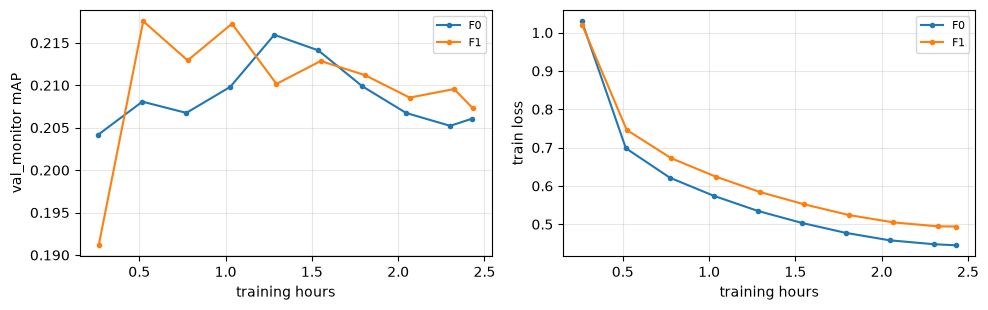

In [3]:
runs.plot_curves(["F0", "F1"]);

Observation: TODO

## 3. Anchor coverage: default (32-512) vs 16-256
Share of train boxes (%, 500 frames) whose best anchor IoU at model input reaches 0.5 / 0.4; buckets are COCO sizes in original pixels.

![anchor coverage](../images/anchor_coverage.png)

In [4]:
runs.coverage_table("frcnn").round(1)

iou>=0.5                    iou>=0.4                    
bucket     small medium large   all    small medium  large   all
anchors                                                         
16-256      89.6   98.6  98.9  96.4     93.1  100.0  100.0  98.3
default     19.8   87.3  99.7  71.8     33.3   93.7  100.0  79.2

Observation: TODO

## 4. RPN proposals vs final detections (F0)
Recall at IoU 0.5 on 100 random val frames: top-1000 RPN proposals, final boxes of any class, final boxes of the right class.

![rpn recall](../images/frcnn_rpn_recall.png)

In [5]:
stages = runs.load_analysis("frcnn_stages")
pd.DataFrame(stages["recall"]).round(1)

,small,medium,large,all
rpn proposals,63.2,77.4,98.8,76.4
"final, any class",59.3,75.0,97.0,73.8
"final, same class",56.6,70.8,95.4,70.2
n ground truth,921.0,2681.0,434.0,4036.0


Observation: TODO

## 5. TIDE error breakdown (F0)

![F0 TIDE](../images/F0_tide.png)

In [6]:
f0 = runs.load_analysis("F0_failures")
pd.Series({**f0["tide"]["main"], **f0["tide"]["special"]}, name="dAP50").round(2).to_frame().T

,Cls,Loc,Both,Dupe,Bkg,Miss,FalsePos,FalseNeg
dAP50,12.35,5.25,0.9,0.02,3.36,9.64,30.57,17.22


Observation: TODO

## 6. Failure gallery (F0)
Frames with the most missed small objects, class confusions and duplicates; GT green, predictions with score >= 0.3 red.

![F0 fail 1](../images/F0_fail_1.png)
![F0 fail 2](../images/F0_fail_2.png)
![F0 fail 3](../images/F0_fail_3.png)

In [7]:
pd.DataFrame(f0["gallery"]).set_index("n")

,kind,frame,missed_small,confusions,duplicates
n,,,,,
1,missed_small,uav0000182_00000_v/0000227,22,11,0
2,confusions,uav0000182_00000_v/0000238,13,24,0
3,duplicates,uav0000086_00000_v/0000017,3,0,3


Observation: TODO